In [1]:
python     %pip install pandas numpy matplotlib scikit-learn tensorflow


SyntaxError: invalid syntax (4013604131.py, line 1)

In [2]:
%pip install pandas numpy matplotlib scikit-learn tensorflow

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

In [2]:
generation = pd.read_csv("Plant_1_Generation_Data.csv")
weather = pd.read_csv("Plant_1_Weather_Sensor_Data.csv")

print("Generation Data:")
display(generation.head())

print("Weather Data:")
display(weather.head())

Generation Data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


Weather Data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [3]:
generation["DATE_TIME"] = pd.to_datetime(
    generation["DATE_TIME"], dayfirst=True
)

weather["DATE_TIME"] = pd.to_datetime(
    weather["DATE_TIME"], dayfirst=False
)

In [4]:
# Calculate total power at each timestamp
total_power = generation.groupby(
    ["DATE_TIME", "PLANT_ID"], as_index=False
)["AC_POWER"].sum()

# Merge generation data with weather data
df = pd.merge(
    total_power,
    weather,
    on=["DATE_TIME", "PLANT_ID"],
    how="inner"
)

# Sort by time
df = df.sort_values("DATE_TIME").reset_index(drop=True)

print("Merged Dataset:")
display(df.head())

print("Total records:", len(df))

Merged Dataset:


,DATE_TIME,PLANT_ID,AC_POWER,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,0.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,0.0,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,0.0,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,0.0,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,0.0,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


Total records: 3157


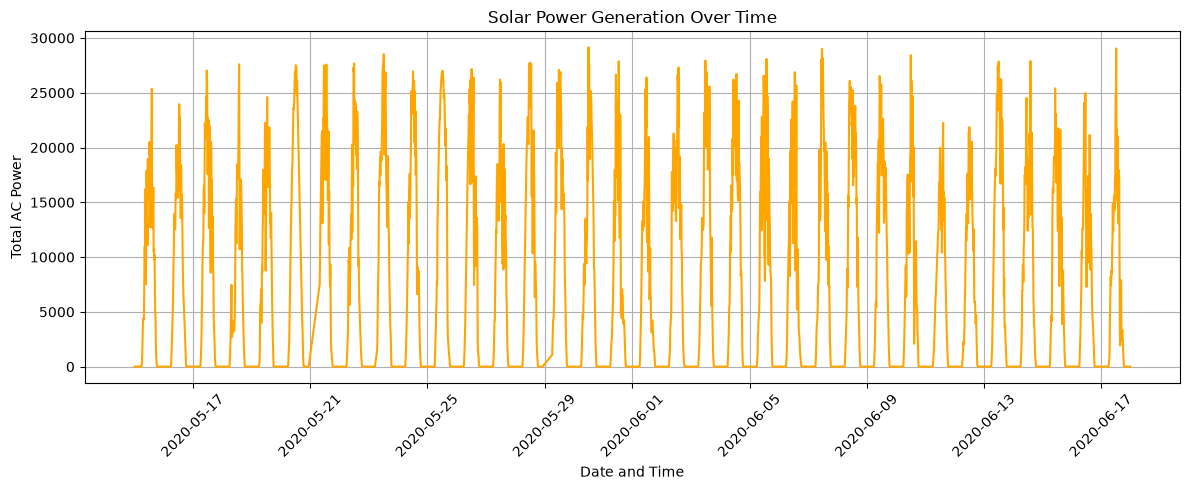

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(df["DATE_TIME"], df["AC_POWER"], color="orange")

plt.title("Solar Power Generation Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Total AC Power")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

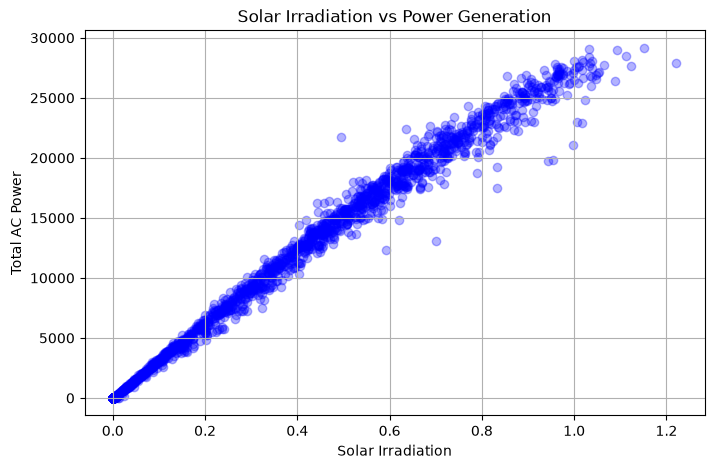

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["IRRADIATION"],
    df["AC_POWER"],
    color="blue",
    alpha=0.3
)

plt.title("Solar Irradiation vs Power Generation")
plt.xlabel("Solar Irradiation")
plt.ylabel("Total AC Power")
plt.grid(True)

plt.show()


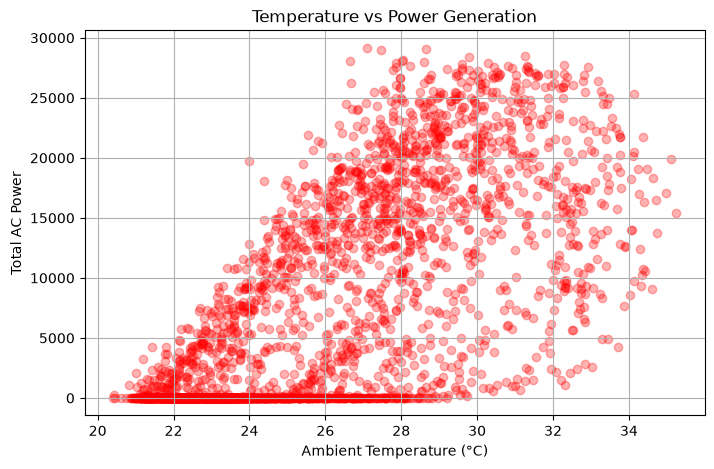

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["AMBIENT_TEMPERATURE"],
    df["AC_POWER"],
    color="red",
    alpha=0.3
)

plt.title("Temperature vs Power Generation")
plt.xlabel("Ambient Temperature (°C)")
plt.ylabel("Total AC Power")
plt.grid(True)

plt.show()

In [8]:
features = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

target = "AC_POWER"

# Remove missing values
df = df.dropna(subset=features + [target])

X = df[features].values
y = df[[target]].values

# 80% training, 20% testing
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2525
Testing samples: 632


In [9]:
# Create scalers
x_scaler = StandardScaler()
y_scaler = StandardScaler()

# Fit using training data only
X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train)
y_test = y_scaler.transform(y_test)

In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │              64 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False
)

Epoch 1/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.7037 - val_loss: 0.3276
Epoch 2/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2282 - val_loss: 0.0874
Epoch 3/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0809 - val_loss: 0.0457
Epoch 4/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0476 - val_loss: 0.0356
Epoch 5/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0321 - val_loss: 0.0297
Epoch 6/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0245 - val_loss: 0.0256
Epoch 7/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0198 - val_loss: 0.0222
Epoch 8/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0165 - val_loss: 0.0202
Epoch 9/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0143 - val_loss: 0.0187
Epoch 10/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0126 - val_loss: 0.0175
Epoch 11/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0114 - val_loss: 0.0165
Epoch 12/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0104 - val_l

In [12]:
# Predict power
predicted = model.predict(X_test)

# Convert predictions to original scale
predicted = y_scaler.inverse_transform(predicted)
actual = y_scaler.inverse_transform(y_test)

print("First 10 predictions:")

results = pd.DataFrame({
    "Actual Power": actual.flatten(),
    "Predicted Power": predicted.flatten()
})

display(results.head(10))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
First 10 predictions:


,Actual Power,Predicted Power
0,9610.560714,9238.716797
1,10287.671429,9882.044922
2,11091.971429,10593.637695
3,12068.066071,11533.654297
4,12320.907143,12111.187500
5,12771.435714,12444.398438
6,15504.928571,15056.789062
7,16784.860714,16282.953125
8,15787.112500,15240.525391
9,17764.082143,17019.855469


In [13]:
mae = mean_absolute_error(actual, predicted)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 344.08


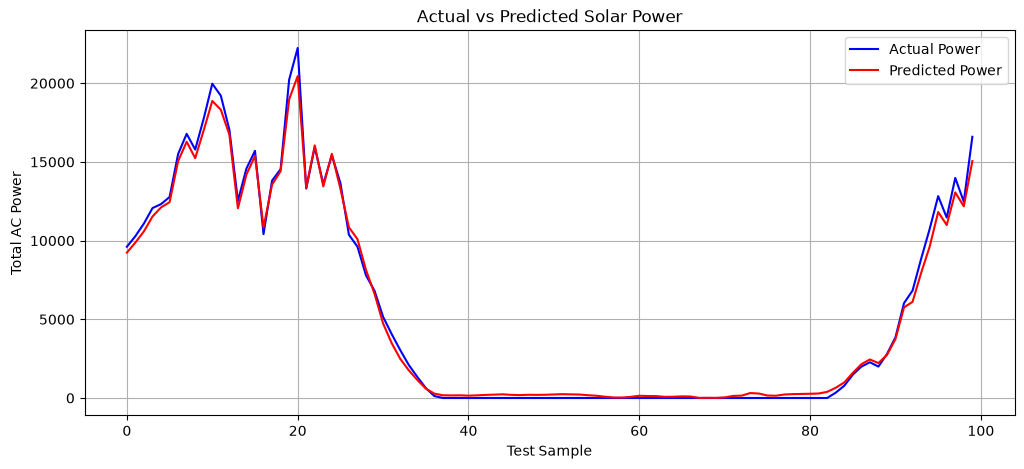

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(actual[:100], label="Actual Power", color="blue")
plt.plot(predicted[:100], label="Predicted Power", color="red")

plt.title("Actual vs Predicted Solar Power")
plt.xlabel("Test Sample")
plt.ylabel("Total AC Power")
plt.legend()
plt.grid(True)

plt.show()

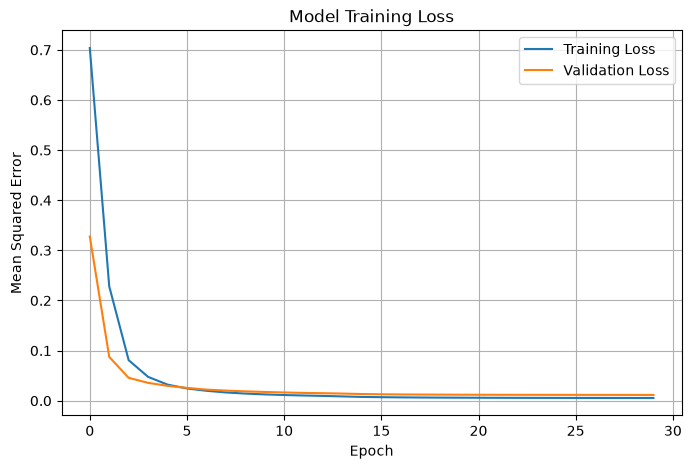

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.show()